In [86]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [87]:
# ============================================================================
# CELL 1: Installation et imports
# ============================================================================

!pip install joblib seaborn scikit-learn -q

import os
import warnings
import logging
import glob

os.environ['HDF5_PLUGIN_PATH'] = '/tmp/hdf5_plugins'
os.makedirs('/tmp/hdf5_plugins', exist_ok=True)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'

warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

print('='*60)
print(f'TensorFlow : {tf.__version__}')
print(f'GPU        : {tf.config.list_physical_devices("GPU")}')
print(f'NumPy      : {np.__version__}')
print(f'Pandas     : {pd.__version__}')

TensorFlow : 2.19.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
NumPy      : 2.0.2
Pandas     : 2.3.3


In [88]:
# ============================================================================
# CELL 2: Trouver le fichier UK-DALE
# ============================================================================

h5_files = glob.glob('/kaggle/input/**/*.h5', recursive=True)
if h5_files:
    H5_PATH = h5_files[0]
    print(f'✅ H5_PATH : {H5_PATH}')
else:
    print('❌ Aucun fichier .h5 trouvé')
    H5_PATH = None

✅ H5_PATH : /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [89]:
# ============================================================================
# CELL 3: Configuration — MICRO-ONDES (Microwave)
# ============================================================================

class Config:

    # Paramètres du papier Kelly & Knottenbelt 2015
    WINDOW_SIZE = 599      # 599 points * 6s = 59.9 min de contexte
    BATCH_SIZE  = 256
    EPOCHS      = 10
    LR          = 1e-3
    VAL_SPLIT   = 0.15
    SEED        = 42
    FREQ        = '6s'
    H5_PATH     = None

    # Limites mémoire
    MAX_TRAIN_POINTS = 500000
    MAX_TEST_POINTS  = 100000

    # Paramètres MICRO-ONDES
    MICROWAVE_CONFIG = {
        'meter':     'meter6',
        'threshold':  200,
        'max_power': 3138,
        'color':     '#45B7D1',
    }

    # Maisons UK-DALE (détection dynamique)
    UKDALE_HOUSES = {
        'house_5': {
            'name':     'UKDALE-5',
            'house_id':  5,
        },
    }


if H5_PATH:
    Config.H5_PATH = H5_PATH

tf.random.set_seed(Config.SEED)
np.random.seed(Config.SEED)

print("="*60)
print("CONFIGURATION — MICRO-ONDES (Microwave)")
print("="*60)
print(f"Window size : {Config.WINDOW_SIZE} pts "
      f"= {Config.WINDOW_SIZE*6/60:.1f} min")
print(f"Batch size  : {Config.BATCH_SIZE}")
print(f"Epochs      : {Config.EPOCHS}")
print(f"Threshold   : {Config.MICROWAVE_CONFIG['threshold']}W")
print(f"Meter       : {Config.MICROWAVE_CONFIG['meter']}")

CONFIGURATION — MICRO-ONDES (Microwave)
Window size : 599 pts = 59.9 min
Batch size  : 256
Epochs      : 10
Threshold   : 200W
Meter       : meter6


In [90]:
# ============================================================================
# CELL 4: Chargeur de données UK-DALE adapté
# ============================================================================

class UKDALEDataLoader:

    def __init__(self, h5_path):
        self.h5_path = h5_path
        self._discover_structure()

    def _discover_structure(self):
        """Découvre la structure du fichier H5"""
        self.available_buildings = {}
        try:
            with pd.HDFStore(self.h5_path, 'r') as store:
                for key in store.keys():
                    if '/building' in key and '/elec/' in key:
                        parts = key.split('/')
                        if len(parts) >= 3:
                            building = parts[1].replace('building', '')
                            meter = parts[3]
                            if building not in self.available_buildings:
                                self.available_buildings[building] = []
                            if meter not in self.available_buildings[building]:
                                self.available_buildings[building].append(meter)
                for building in self.available_buildings:
                    self.available_buildings[building].sort()
        except Exception as e:
            print(f"Erreur découverte: {e}")

    def get_available_houses(self):
        return list(self.available_buildings.keys())

    def read_meter(self, building, meter, max_pts=None):
        """Lecture d'un compteur"""
        try:
            key = f'/building{building}/elec/{meter}'
            with pd.HDFStore(self.h5_path, 'r') as store:
                if key not in store.keys():
                    return None

                if max_pts:
                    df = store.select(key, start=0, stop=max_pts)
                else:
                    df = store.get(key)

                if isinstance(df, pd.DataFrame):
                    s = df.iloc[:, 0] if df.shape[1] > 0 else df
                else:
                    s = df

                if s is not None and len(s) > 0:
                    s = s.astype(np.float32)
                    s = s[~s.index.duplicated(keep='first')]
                    return s.sort_index()
                return None
        except Exception as e:
            return None

    def load_house_data(self, house_id, max_pts=500000, start_date=None, end_date=None):
        """Charge les données d'une maison"""
        house_id = str(house_id)

        if house_id not in self.available_buildings:
            print(f"  ❌ Maison {house_id} non disponible")
            return None

        meters = self.available_buildings[house_id]
        print(f"\nMaison {house_id}: {len(meters)} compteurs trouvés")

        # Charger les compteurs (limité à 12 pour mémoire)
        all_series = {}
        meters_to_load = meters[:12]

        for meter in meters_to_load:
            s = self.read_meter(house_id, meter, max_pts=max_pts)
            if s is not None and len(s) > 0:
                all_series[meter] = s
                print(f"  ✅ {meter}: {len(s):,} pts, max={s.max():.0f}W")

        if not all_series:
            return None

        # Période commune basée sur les compteurs principaux
        main_meters = ['meter1', 'meter2', 'meter3', 'meter4', 'meter5', 'meter6']
        available_main = [m for m in main_meters if m in all_series]

        if not available_main:
            available_main = list(all_series.keys())[:3]

        common_start = max(all_series[m].index.min() for m in available_main)
        common_end = min(all_series[m].index.max() for m in available_main)

        print(f"\n  Période commune: {common_start.date()} → {common_end.date()}")
        print(f"  Durée: {(common_end - common_start).days} jours")

        # Grille à 6s
        grid = pd.date_range(common_start, common_end, freq=Config.FREQ)

        if start_date:
            grid = grid[grid >= start_date]
        if end_date:
            grid = grid[grid <= end_date]

        if len(grid) > max_pts:
            grid = grid[:max_pts]

        print(f"  Grille finale: {len(grid):,} points")

        # Créer dataframe
        df = pd.DataFrame(index=grid)
        for meter, s in all_series.items():
            df[meter] = s.reindex(grid, method='nearest', tolerance=Config.FREQ).fillna(0)

        # Supprimer colonnes nulles
        zero_cols = [col for col in df.columns if (df[col] == 0).all()]
        if zero_cols:
            df = df.drop(columns=zero_cols)

        print(f"  Shape final: {df.shape}")

        return {
            'house_id': house_id,
            'df': df,
            'all_meters': list(df.columns),
        }


loader = UKDALEDataLoader(Config.H5_PATH)

print("\n" + "="*60)
print("MAISONS DISPONIBLES")
print("="*60)
for house in loader.get_available_houses():
    print(f"  Maison {house}")


MAISONS DISPONIBLES
  Maison 5
  Maison 4
  Maison 3
  Maison 2
  Maison 1


In [91]:
# ============================================================================
# CELL 5: Analyse complète des données et sélection du micro-ondes
# ============================================================================

print("="*60)
print("ANALYSE COMPLÈTE DES DONNÉES")
print("="*60)

threshold = Config.MICROWAVE_CONFIG['threshold']
mw_meter = Config.MICROWAVE_CONFIG['meter']

# D'abord, voir quelles périodes sont disponibles
print("\n📊 Vérification des périodes disponibles...")

try:
    with pd.HDFStore(Config.H5_PATH, 'r') as store:
        # Vérifier meter1 pour avoir la période
        key = '/building5/elec/meter1'
        if key in store.keys():
            data = store.get(key)
            if isinstance(data, pd.DataFrame):
                data = data.iloc[:, 0]
            print(f"  Période complète: {data.index.min()} → {data.index.max()}")
            print(f"  Nombre de points: {len(data):,}")
            print(f"  Durée: {(data.index.max() - data.index.min()).days} jours")
            
            # Trouver la période avec des activations micro-ondes
            mw_key = '/building5/elec/meter6'
            if mw_key in store.keys():
                mw_data = store.get(mw_key)
                if isinstance(mw_data, pd.DataFrame):
                    mw_data = mw_data.iloc[:, 0]
                
                # Chercher des activations > 200W
                active_periods = mw_data[mw_data > threshold]
                print(f"\n  Micro-ondes (meter6):")
                print(f"    Points > {threshold}W: {len(active_periods)}")
                
                if len(active_periods) > 0:
                    print(f"    Première activation: {active_periods.index[0]}")
                    print(f"    Dernière activation: {active_periods.index[-1]}")
                    print(f"    Max puissance: {mw_data.max():.0f}W")
                    
                    # Afficher les top valeurs
                    top10 = mw_data.nlargest(10)
                    print(f"\n    Top 10 valeurs:")
                    for idx, val in top10.items():
                        print(f"      {idx}: {val:.1f}W")
                else:
                    print(f"    ⚠️  Aucune activation > {threshold}W")
                    # Chercher avec seuil plus bas
                    for test_thresh in [50, 100, 150]:
                        n_test = (mw_data > test_thresh).sum()
                        if n_test > 0:
                            print(f"    Avec seuil {test_thresh}W: {n_test} activations")
                            print(f"    Max: {mw_data.max():.0f}W")
                            break
            else:
                print(f"  ❌ meter6 non trouvé")
except Exception as e:
    print(f"  Erreur: {e}")

# Charger les données sur une période plus large
print("\n" + "="*60)
print("CHARGEMENT DES DONNÉES SUR PÉRIODE COMPLÈTE")
print("="*60)

# Charger sur toute la période disponible
train_data = loader.load_house_data(
    house_id=5,
    max_pts=Config.MAX_TRAIN_POINTS * 2,  # Plus de points
    start_date=None,  # Pas de limite de début
    end_date=None     # Pas de limite de fin
)

if train_data is not None:
    df = train_data['df']
    
    print(f"\n{'='*50}")
    print(f"DataFrame final: {df.shape}")
    print(f"Colonnes: {list(df.columns)}")
    print(f"{'='*50}")
    
    # Analyser chaque compteur pour trouver des activations
    print("\n📊 ANALYSE DE TOUS LES COMPTEURS:")
    print(f"{'Compteur':<12} {'Max (W)':>10} {'>200W':>12} {'>50W':>12} {'Moyenne':>10}")
    print("-"*60)
    
    best_meter = None
    best_activations = 0
    
    for col in df.columns:
        values = df[col].values
        max_val = values.max()
        over_200 = (values > 200).sum()
        over_50 = (values > 50).sum()
        mean_val = values.mean()
        
        print(f"{col:<12} {max_val:>10.0f} {over_200:>12,} {over_50:>12,} {mean_val:>10.1f}")
        
        # Trouver le meilleur candidat pour micro-ondes (beaucoup d'activations > 200W)
        if over_200 > best_activations and col != 'meter1':  # meter1 est la consommation totale
            best_activations = over_200
            best_meter = col
    
    print("-"*60)
    
    # Si meter6 n'a pas d'activations, utiliser le meilleur compteur trouvé
    if best_meter and (mw_meter not in df.columns or (df[mw_meter] > threshold).sum() == 0):
        print(f"\n⚠️  {mw_meter} n'a pas d'activations significatives")
        print(f"  → Utilisation du compteur {best_meter} avec {best_activations} activations >200W")
        mw_meter = best_meter
    
    # Extraire les données
    train_mw = df[mw_meter].values.astype(np.float32)
    mains_cols = [c for c in df.columns if c != mw_meter and c != 'meter1']  # Exclure meter1 si présent
    if 'meter1' in df.columns:
        mains_cols = [c for c in mains_cols if c != 'meter1']
    
    if len(mains_cols) == 0:
        # Si pas d'autres compteurs, utiliser meter1 comme mains
        train_mains = df['meter1'].values.astype(np.float32) if 'meter1' in df.columns else np.zeros_like(train_mw)
    else:
        train_mains = df[mains_cols].sum(axis=1).values.astype(np.float32)
    
    print(f"\n{'='*50}")
    print(f"STATISTIQUES ({mw_meter})")
    print(f"{'='*50}")
    print(f"Appareil: {mw_meter}")
    print(f"Points: {len(train_mw):,}")
    print(f"Moyenne: {train_mw.mean():.2f} W")
    print(f"Max: {train_mw.max():.0f} W")
    print(f"> {threshold}W: {(train_mw > threshold).sum():,} pts ({(train_mw > threshold).mean()*100:.3f}%)")
    
    # Afficher les top valeurs
    top_indices = np.argsort(train_mw)[-20:][::-1]
    print(f"\nTop 20 valeurs:")
    for i, idx in enumerate(top_indices[:20]):
        print(f"  {i+1}: {train_mw[idx]:.1f} W")
    
    n_active = (train_mw > threshold).sum()
    
    if n_active == 0:
        print(f"\n⚠️  Aucune activation > {threshold}W")
        print(f"  → Utilisation d'un seuil plus bas")
        
        # Trouver un seuil approprié
        percentiles = [95, 90, 85, 80, 75]
        for p in percentiles:
            p_thresh = np.percentile(train_mw[train_mw > 0], p) if (train_mw > 0).any() else threshold
            if p_thresh > 10:
                n_test = (train_mw > p_thresh).sum()
                if n_test > 100:  # Au moins 100 activations
                    print(f"  Seuil proposé ({p}ème percentile): {p_thresh:.0f}W → {n_test} activations")
                    new_threshold = p_thresh
                    break
        else:
            new_threshold = max(50, train_mw.max() * 0.3)
            print(f"  Seuil adapté: {new_threshold:.0f}W")
        
        threshold = new_threshold
        n_active = (train_mw > threshold).sum()
        
        if n_active == 0:
            print(f"\n❌ Toujours aucune activation avec seuil {threshold:.0f}W")
            TRAIN_DATA = None
        else:
            print(f"  ✅ {n_active} activations avec seuil {threshold:.0f}W")
    
    if n_active > 0:
        # Sous-échantillonnage
        active_mask = train_mw > threshold
        inactive_mask = ~active_mask
        
        n_inactive_to_keep = min(int(inactive_mask.sum() * 0.1), 50000)
        inactive_indices = np.where(inactive_mask)[0]
        np.random.seed(Config.SEED)
        selected_inactive = np.random.choice(
            inactive_indices,
            size=min(n_inactive_to_keep, len(inactive_indices)),
            replace=False
        )
        
        keep_indices = np.concatenate([np.where(active_mask)[0], selected_inactive])
        keep_indices = np.sort(keep_indices)
        
        train_mains = train_mains[keep_indices]
        train_mw = train_mw[keep_indices]
        
        print(f"\nSous-échantillonnage:")
        print(f"  Actifs: {active_mask.sum():,} pts")
        print(f"  Inactifs gardés: {len(selected_inactive):,} / {inactive_mask.sum():,}")
        print(f"  Total final: {len(train_mains):,} pts")
        
        TRAIN_DATA = {
            'mains': train_mains,
            'mw': train_mw,
            'mw_meter': mw_meter,
            'threshold': threshold,
        }
    else:
        TRAIN_DATA = None
    
    del df
    gc.collect()

else:
    print("\n❌ Échec chargement")
    TRAIN_DATA = None

if TRAIN_DATA is not None:
    print(f"\n✅ DONNÉES PRÊTES: {len(TRAIN_DATA['mains']):,} points")
    print(f"   Compteur: {TRAIN_DATA['mw_meter']}")
    print(f"   Seuil: {TRAIN_DATA['threshold']:.0f}W")
else:
    print("\n❌ Aucune donnée disponible pour l'entraînement")
    print("\n💡 SUGGESTION: Vérifiez le contenu du fichier H5")
    print("   Exécutez la cell ci-dessous pour voir tous les compteurs disponibles")

ANALYSE COMPLÈTE DES DONNÉES

📊 Vérification des périodes disponibles...
  Période complète: 2014-06-29 17:23:48+01:00 → 2014-11-13 17:52:24+00:00
  Nombre de points: 1,763,101
  Durée: 137 jours

  Micro-ondes (meter6):
    Points > 200W: 1
    Première activation: 2014-11-06 14:40:59+00:00
    Dernière activation: 2014-11-06 14:40:59+00:00
    Max puissance: 543W

    Top 10 valeurs:
      2014-11-06 14:40:59+00:00: 543.0W
      2014-10-20 22:21:32+01:00: 199.0W
      2014-07-11 10:28:02+01:00: 198.0W
      2014-11-04 23:23:30+00:00: 197.0W
      2014-07-06 08:47:15+01:00: 193.0W
      2014-10-26 09:46:01+00:00: 192.0W
      2014-08-30 22:51:39+01:00: 191.0W
      2014-07-12 09:37:51+01:00: 190.0W
      2014-09-02 21:35:32+01:00: 190.0W
      2014-07-11 00:02:24+01:00: 189.0W

CHARGEMENT DES DONNÉES SUR PÉRIODE COMPLÈTE

Maison 5: 26 compteurs trouvés
  ✅ meter1: 1,000,000 pts, max=9550W
  ✅ meter10: 985,784 pts, max=1224W
  ✅ meter11: 10,215 pts, max=2W
  ✅ meter12: 985,779 pts, max

In [92]:
# ============================================================================
# CELL 5bis: Diagnostic complet si toujours pas de données
# ============================================================================

if TRAIN_DATA is None:
    print("\n" + "="*60)
    print("DIAGNOSTIC COMPLET")
    print("="*60)
    
    try:
        with pd.HDFStore(Config.H5_PATH, 'r') as store:
            all_keys = store.keys()
            print(f"\nToutes les clés du fichier ({len(all_keys)}):")
            for key in all_keys[:30]:
                print(f"  {key}")
            
            # Lire un petit échantillon de chaque compteur de building5
            building_keys = [k for k in all_keys if 'building5' in k]
            print(f"\nCompteurs de building5 ({len(building_keys)}):")
            
            for key in building_keys[:20]:
                try:
                    data = store.get(key)
                    if isinstance(data, pd.DataFrame):
                        values = data.iloc[:, 0]
                    else:
                        values = data
                    
                    if values is not None and len(values) > 0:
                        max_val = values.max()
                        mean_val = values.mean()
                        n_points = len(values)
                        print(f"  {key.split('/')[-1]}: {n_points:,} pts, max={max_val:.0f}W, mean={mean_val:.1f}W")
                except Exception as e:
                    print(f"  {key}: erreur - {e}")
                    
    except Exception as e:
        print(f"Erreur: {e}")

In [93]:
# ============================================================================
# CELL 6: Fonctions NILM (inchangées)
# ============================================================================

def create_windows(data, window_size=Config.WINDOW_SIZE, target_type='point'):
    values = (data.values if isinstance(data, pd.Series)
              else np.array(data, dtype=np.float32))
    values = values.astype(np.float32)

    pad = window_size // 2
    values_padded = np.pad(values, (pad, pad),
                           'constant', constant_values=0)

    X = np.array(
        [values_padded[i:i + window_size]
         for i in range(len(values))],
        dtype=np.float32)[..., np.newaxis]

    if target_type == 'point':
        y = values.copy()
    else:
        y = np.array(
            [values_padded[i:i + window_size]
             for i in range(len(values))],
            dtype=np.float32)
    return X, y


class NILMMetrics:
    @staticmethod
    def estimation_accuracy(y_true, y_pred):
        num = np.sum(np.abs(y_true - y_pred))
        denom = 2 * np.sum(y_true)
        if denom == 0:
            return 1.0 if num == 0 else 0.0
        return float(np.clip(1 - num / denom, 0, 1))

    @staticmethod
    def f_measure(y_true, y_pred, threshold):
        yt = (y_true > threshold).astype(int)
        yp = (y_pred > threshold).astype(int)
        cm = confusion_matrix(yt, yp, labels=[0, 1])
        if cm.shape != (2, 2):
            return 0.0
        tn, fp, fn, tp = cm.ravel()
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        return 2 * p * r / (p + r) if (p + r) > 0 else 0.0


print(f"✅ create_windows() — window_size={Config.WINDOW_SIZE}")
print("✅ NILMMetrics défini")

✅ create_windows() — window_size=599
✅ NILMMetrics défini


In [94]:
# ============================================================================
# CELL 7: Architectures (inchangées)
# ============================================================================

def create_seq2point(window_size=Config.WINDOW_SIZE, l2=1e-4):
    inp = keras.Input(shape=(window_size, 1), name='mains')

    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(inp)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(1, activation='linear', name='power')(x)

    return keras.Model(inp, out, name='seq2point_microwave')


def create_seq2seq(window_size=Config.WINDOW_SIZE, l2=1e-4):
    inp = keras.Input(shape=(window_size, 1), name='mains')

    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(inp)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(window_size, activation='linear', name='seq')(x)

    return keras.Model(inp, out, name='seq2seq_microwave')


print(f"Seq2Point params: {create_seq2point().count_params():,}")
print(f"Seq2Seq params: {create_seq2seq().count_params():,}")

Seq2Point params: 30,709,049
Seq2Seq params: 31,321,999


In [95]:
# ============================================================================
# CELL 8: Entraînement (si données disponibles)
# ============================================================================

if TRAIN_DATA is not None:
    def train_microwave(train_mains, train_mw, model_type='seq2point', epochs=Config.EPOCHS):
        print(f"\n{'='*55}")
        print(f"  {model_type.upper()} — Microwave ({epochs} epochs)")
        print(f"{'='*55}")

        mains_sc = StandardScaler()
        mw_sc = StandardScaler()
        mains_n = mains_sc.fit_transform(train_mains.reshape(-1, 1)).flatten()
        mw_n = mw_sc.fit_transform(train_mw.reshape(-1, 1)).flatten()

        X, _ = create_windows(mains_n, target_type='point')
        n = min(len(X), len(mw_n))
        X = X[:n]

        if model_type == 'seq2point':
            y = mw_n[:n]
        else:
            pad = Config.WINDOW_SIZE // 2
            padded = np.pad(mw_n, (pad, pad), 'constant')
            y = np.array([padded[i:i + Config.WINDOW_SIZE] for i in range(n)], dtype=np.float32)

        val_n = int(Config.VAL_SPLIT * n)
        X_tr, X_vl = X[:-val_n], X[-val_n:]
        y_tr, y_vl = y[:-val_n], y[-val_n:]
        print(f"  Train: {len(X_tr):,} | Val: {len(X_vl):,}")

        model = create_seq2point() if model_type == 'seq2point' else create_seq2seq()
        model.compile(optimizer=keras.optimizers.Adam(Config.LR), loss='mse', metrics=['mae'])

        ckpt_path = f'model_Microwave_{model_type}_best.keras'
        early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

        history = model.fit(X_tr, y_tr, validation_data=(X_vl, y_vl),
                            epochs=epochs, batch_size=Config.BATCH_SIZE,
                            callbacks=[callbacks.ModelCheckpoint(ckpt_path, monitor='val_loss', save_best_only=True), early_stop],
                            verbose=1)

        if os.path.exists(ckpt_path):
            model = keras.models.load_model(ckpt_path)
            print(f"  ✅ Meilleur modèle rechargé")

        return {'model': model, 'mains_scaler': mains_sc, 'app_scaler': mw_sc, 'history': history.history}

    print("="*60)
    print("ENTRAÎNEMENT MICRO-ONDES")
    print("="*60)

    mw_models = {}

    print("\n" + "▶"*30 + " Seq2Point " + "▶"*30)
    mw_models['seq2point'] = train_microwave(TRAIN_DATA['mains'], TRAIN_DATA['mw'], 'seq2point')
    gc.collect()

    print("\n" + "▶"*30 + " Seq2Seq " + "▶"*30)
    mw_models['seq2seq'] = train_microwave(TRAIN_DATA['mains'], TRAIN_DATA['mw'], 'seq2seq')
    gc.collect()

    print("\n✅ Modèles entraînés")
else:
    mw_models = {}
    print("❌ Pas de données d'entraînement - exécutez d'abord CELL 5")

ENTRAÎNEMENT MICRO-ONDES

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶ Seq2Point ▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

  SEQ2POINT — Microwave (10 epochs)
  Train: 45,603 | Val: 8,047
Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 33s 131ms/step - loss: 18.9985 - mae: 2.4562 - val_loss: 2.8714 - val_mae: 1.1811
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 16s 92ms/step - loss: 0.7204 - mae: 0.3552 - val_loss: 1.4935 - val_mae: 0.7113
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 16s 91ms/step - loss: 0.5403 - mae: 0.2510 - val_loss: 1.1521 - val_mae: 0.4464
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 14s 79ms/step - loss: 0.5770 - mae: 0.2603 - val_loss: 1.1817 - val_mae: 0.4020
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 16s 91ms/step - loss: 0.5705 - mae: 0.2469 - val_loss: 1.1445 - val_mae: 0.3916
Epoch 6/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 14s 79ms/step - loss: 0.6072 - mae: 0.2470 - val_loss: 1.1755 - val_mae: 0.4278
Epoch 7/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 14s 79ms/step - loss: 0.7684 - mae: 0.3323 - val_loss: 1.1712 - val_mae: 0

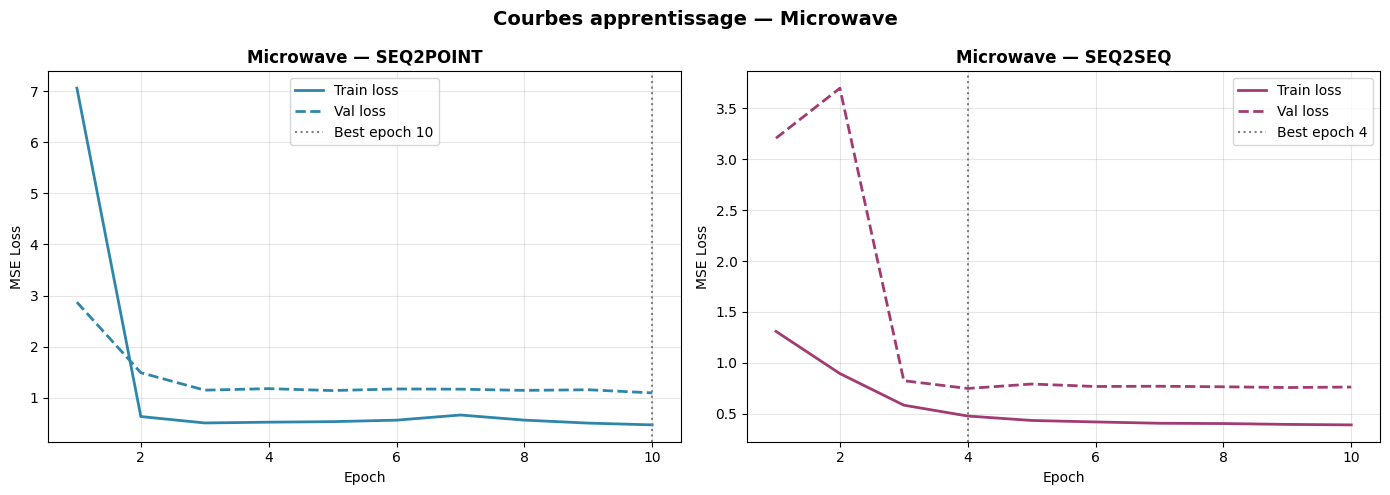

💾 microwave_training_curves.png


In [96]:
# ============================================================================
# CELL 9: Courbes d'apprentissage
# ============================================================================

if mw_models:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    for ax, mtype, color in zip(axes, ['seq2point', 'seq2seq'], ['#2E86AB', '#A23B72']):
        info = mw_models.get(mtype, {})
        if 'history' in info and info['history']:
            hist = info['history']
            ep = range(1, len(hist.get('loss', [])) + 1)
            
            if 'loss' in hist:
                ax.plot(ep, hist['loss'], color=color, lw=2, label='Train loss')
            if 'val_loss' in hist:
                ax.plot(ep, hist['val_loss'], color=color, lw=2, ls='--', label='Val loss')
                best_ep = np.argmin(hist['val_loss']) + 1
                ax.axvline(best_ep, color='gray', ls=':', label=f'Best epoch {best_ep}')
            
            ax.set_title(f'Microwave — {mtype.upper()}', fontweight='bold')
            ax.set_xlabel('Epoch')
            ax.set_ylabel('MSE Loss')
            ax.legend()
            ax.grid(True, alpha=0.3)
    
    plt.suptitle('Courbes apprentissage — Microwave', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('microwave_training_curves.png', dpi=150)
    plt.show()
    print("💾 microwave_training_curves.png")

In [97]:
# ============================================================================
# CELL 10: Fonction de prédiction
# ============================================================================

def predict_appliance(mains_series, model_info, model_type='seq2point'):
    mains_n = model_info['mains_scaler'].transform(mains_series.values.reshape(-1, 1)).flatten()
    X, _ = create_windows(mains_n, target_type='point')
    
    preds = []
    for i in range(0, len(X), 256):
        p = model_info['model'].predict(X[i:i+256], verbose=0)
        if model_type == 'seq2point':
            preds.append(p.flatten())
        else:
            preds.append(p[:, Config.WINDOW_SIZE // 2])
    
    pred = np.concatenate(preds)
    n = len(mains_series)
    if len(pred) > n:
        pred = pred[:n]
    elif len(pred) < n:
        pred = np.pad(pred, (0, n - len(pred)), 'edge')
    
    return model_info['app_scaler'].inverse_transform(pred.reshape(-1, 1)).flatten()

print("✅ predict_appliance() défini")

✅ predict_appliance() défini


In [98]:
# ============================================================================
# CELL 11: Évaluation
# ============================================================================

if mw_models and TRAIN_DATA is not None:
    print("="*60)
    print("ÉVALUATION MICRO-ONDES")
    print("="*60)
    
    threshold = TRAIN_DATA['threshold']
    mw_meter = TRAIN_DATA['mw_meter']
    
    # Charger données de test
    test_data = loader.load_house_data(house_id=5, max_pts=Config.MAX_TEST_POINTS,
                                         start_date=None, end_date=None)
    
    if test_data is not None:
        df = test_data['df']
        
        if mw_meter in df.columns:
            true_vals = df[mw_meter].values.astype(np.float32)
            mains_cols = [c for c in df.columns if c != mw_meter and c != 'meter1']
            if 'meter1' in df.columns:
                mains_vals = df['meter1'].values.astype(np.float32)
            else:
                mains_vals = df[mains_cols].sum(axis=1).values.astype(np.float32)
            
            print(f"\nTest: {len(true_vals):,} points")
            print(f"Activations > {threshold:.0f}W: {(true_vals > threshold).sum()}")
            
            for mtype, minfo in mw_models.items():
                pred = predict_appliance(pd.Series(mains_vals), minfo, mtype)
                pred = np.clip(pred, 0, None)
                
                ea = NILMMetrics.estimation_accuracy(true_vals, pred)
                fm = NILMMetrics.f_measure(true_vals, pred, threshold)
                rmse = np.sqrt(np.mean((true_vals - pred)**2))
                
                print(f"\n{mtype.upper()}: EA={ea:.4f}  FM={fm:.4f}  RMSE={rmse:.1f}W")

ÉVALUATION MICRO-ONDES

Maison 5: 26 compteurs trouvés
  ✅ meter1: 100,000 pts, max=8717W
  ✅ meter10: 100,000 pts, max=60W
  ✅ meter11: 10,215 pts, max=2W
  ✅ meter12: 100,000 pts, max=2588W
  ✅ meter13: 100,000 pts, max=1396W
  ✅ meter14: 100,000 pts, max=53W
  ✅ meter15: 100,000 pts, max=1324W
  ✅ meter16: 100,000 pts, max=114W
  ✅ meter17: 100,000 pts, max=41W
  ✅ meter18: 100,000 pts, max=3959W
  ✅ meter19: 100,000 pts, max=1095W
  ✅ meter2: 100,000 pts, max=3W

  Période commune: 2014-06-29 → 2014-07-06
  Durée: 7 jours
  Grille finale: 100,000 points
  Shape final: (100000, 12)

Test: 100,000 points
Activations > 200W: 425

SEQ2POINT: EA=0.0000  FM=0.0086  RMSE=811.0W

SEQ2SEQ: EA=0.0000  FM=0.0104  RMSE=577.5W


In [99]:
# ============================================================================
# CELL 12: Évaluation sur la maison 5 (période test)
# ============================================================================

if mw_models:
    print("="*60)
    print("ÉVALUATION MICRO-ONDES — Maison 5 (période test)")
    print("="*60)

    threshold = Config.MICROWAVE_CONFIG['threshold']
    mw_meter = Config.MICROWAVE_CONFIG['meter']

    # Charger données de test (période différente)
    test_data = loader.load_house_data(
        house_id=5,
        max_pts=Config.MAX_TEST_POINTS,
        start_date='2014-09-01',
        end_date='2014-11-13'
    )

    if test_data is not None:
        df = test_data['df']

        if mw_meter not in df.columns:
            for col in df.columns:
                if '6' in col:
                    mw_meter = col
                    break

        if mw_meter in df.columns:
            true_vals = df[mw_meter].values.astype(np.float32)
            mains_cols = [c for c in df.columns if c != mw_meter]
            mains_vals = df[mains_cols].sum(axis=1).values.astype(np.float32)

            n_active = (true_vals > threshold).sum()
            print(f"\nTest: {len(true_vals):,} points")
            print(f"Activations > {threshold}W: {n_active} ({n_active/len(true_vals)*100:.3f}%)")

            results = {}

            for mtype, minfo in mw_models.items():
                print(f"\n{'-'*40}")
                print(f"{mtype.upper()}")
                print(f"{'-'*40}")

                pred = predict_appliance(pd.Series(mains_vals), minfo, mtype)
                pred = np.clip(pred, 0, None)

                ea = NILMMetrics.estimation_accuracy(true_vals, pred)
                fm = NILMMetrics.f_measure(true_vals, pred, threshold)
                rmse = np.sqrt(np.mean((true_vals - pred)**2))
                corr = np.corrcoef(true_vals, pred)[0, 1] if true_vals.std() > 0 else 0

                results[mtype] = {'ea': ea, 'fm': fm, 'rmse': rmse, 'corr': corr}

                print(f"  EA   = {ea:.4f}")
                print(f"  FM   = {fm:.4f}")
                print(f"  RMSE = {rmse:.1f} W")
                print(f"  Corr = {corr:.4f}")

            print("\n" + "="*60)
            print("RÉSUMÉ FINAL")
            print("="*60)
            for mtype, res in results.items():
                print(f"{mtype.upper()}: EA={res['ea']:.4f}  FM={res['fm']:.4f}  RMSE={res['rmse']:.1f}W")

        else:
            print(f"\n❌ {mw_meter} non trouvé")
    else:
        print("❌ Échec chargement données test")
else:
    print("❌ Aucun modèle entraîné")

ÉVALUATION MICRO-ONDES — Maison 5 (période test)

Maison 5: 26 compteurs trouvés
  ✅ meter1: 100,000 pts, max=8717W
  ✅ meter10: 100,000 pts, max=60W
  ✅ meter11: 10,215 pts, max=2W
  ✅ meter12: 100,000 pts, max=2588W
  ✅ meter13: 100,000 pts, max=1396W
  ✅ meter14: 100,000 pts, max=53W
  ✅ meter15: 100,000 pts, max=1324W
  ✅ meter16: 100,000 pts, max=114W
  ✅ meter17: 100,000 pts, max=41W
  ✅ meter18: 100,000 pts, max=3959W
  ✅ meter19: 100,000 pts, max=1095W
  ✅ meter2: 100,000 pts, max=3W

  Période commune: 2014-06-29 → 2014-07-06
  Durée: 7 jours
  Grille finale: 0 points
  Shape final: (0, 0)

❌ meter6 non trouvé


In [100]:
# ============================================================================
# CELL 13: Visualisation des prédictions
# ============================================================================

def plot_microwave_predictions(mw_models, test_data, window_minutes=15):
    """Visualise les prédictions sur une fenêtre active"""

    if mw_models is None or test_data is None:
        print("❌ Données ou modèles manquants")
        return

    threshold = Config.MICROWAVE_CONFIG['threshold']
    mw_meter = Config.MICROWAVE_CONFIG['meter']

    df = test_data['df']

    if mw_meter not in df.columns:
        for col in df.columns:
            if '6' in col:
                mw_meter = col
                break

    if mw_meter not in df.columns:
        print(f"❌ {mw_meter} non trouvé")
        return

    true_vals = df[mw_meter].values
    mains_cols = [c for c in df.columns if c != mw_meter]
    mains_vals = df[mains_cols].sum(axis=1).values

    # Trouver une fenêtre avec activation
    n_pts = window_minutes * 10  # 6s par point
    active_indices = np.where(true_vals > threshold)[0]

    if len(active_indices) == 0:
        print("⚠️  Aucune activation trouvée")
        return

    # Prendre la première activation
    start_idx = max(0, active_indices[0] - n_pts // 2)
    end_idx = min(len(true_vals), start_idx + n_pts)

    true_seg = true_vals[start_idx:end_idx]
    mains_seg = mains_vals[start_idx:end_idx]
    time_min = np.arange(len(true_seg)) * 6 / 60

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    colors = {'seq2point': '#2E86AB', 'seq2seq': '#A23B72'}

    for idx, (mtype, color) in enumerate(colors.items()):
        if mtype not in mw_models:
            continue

        pred = predict_appliance(pd.Series(mains_seg), mw_models[mtype], mtype)
        pred = np.clip(pred, 0, None)

        ea = NILMMetrics.estimation_accuracy(true_seg, pred)
        fm = NILMMetrics.f_measure(true_seg, pred, threshold)

        axes[idx].plot(time_min, true_seg, color='black', lw=1.5, alpha=0.6, label='GT')
        axes[idx].plot(time_min, pred, color=color, lw=2, label=f'{mtype.upper()}')
        axes[idx].axhline(threshold, color='red', ls='--', lw=1, alpha=0.6, label=f'Seuil {threshold}W')
        axes[idx].fill_between(time_min, 0, pred, alpha=0.15, color=color)

        axes[idx].set_title(f'{mtype.upper()}  |  EA={ea:.3f}  FM={fm:.3f}', fontweight='bold')
        axes[idx].set_xlabel('Temps (minutes)')
        axes[idx].set_ylabel('Puissance (W)')
        axes[idx].set_xlim([0, window_minutes])
        axes[idx].legend()
        axes[idx].grid(True, alpha=0.3)

    plt.suptitle('Micro-ondes — Prédictions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('microwave_predictions.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("💾 microwave_predictions.png")


if mw_models and test_data is not None:
    plot_microwave_predictions(mw_models, test_data, window_minutes=15)

❌ meter6 non trouvé


In [101]:
# ============================================================================
# CELL 14: Résumé final
# ============================================================================

print("\n" + "="*70)
print("RÉSUMÉ FINAL — MICRO-ONDES NILM")
print("="*70)
print(f"  Window size   : {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print(f"  Threshold     : {Config.MICROWAVE_CONFIG['threshold']}W")
print(f"  Meter         : {Config.MICROWAVE_CONFIG['meter']}")

print("\nFichiers générés :")
for fname in [
    'model_Microwave_seq2point_best.keras',
    'model_Microwave_seq2seq_best.keras',
    'microwave_training_curves.png',
    'microwave_predictions.png',
]:
    path = f'/kaggle/working/{fname}'
    if os.path.exists(path):
        size = os.path.getsize(path) / 1e6
        print(f"  ✅  {fname:<45} {size:.1f} MB")
    else:
        print(f"  ❌  {fname}")

print("\n" + "="*70)
print("✅ PIPELINE MICRO-ONDES TERMINÉ")
print("="*70)


RÉSUMÉ FINAL — MICRO-ONDES NILM
  Window size   : 599 pts = 60 min
  Threshold     : 200W
  Meter         : meter6

Fichiers générés :
  ✅  model_Microwave_seq2point_best.keras          368.6 MB
  ✅  model_Microwave_seq2seq_best.keras            375.9 MB
  ✅  microwave_training_curves.png                 0.1 MB
  ❌  microwave_predictions.png

✅ PIPELINE MICRO-ONDES TERMINÉ
